In [ ]:
import networkx as nx
import numpy as np
from scipy.stats import norm

# Определяем связи между точками 
edges_points = {
    'b1(8)': (1, 2),      
    'b2(6)': (1, 3),      
    'b3(13)': (2, 4),     
    'b4(4)': (3, 4),      
    'b5(5)': (3, 5),      
    'b6(10)': (4, 6),     
    'b7(6)': (5, 7),      
    'b8(9)': (6, 8),      
    'b9(10)': (6, 9),     
    'b10(7)': (7, 10),    
    'b11(11)': (9, 11)   
}

# Веса работ 
weights = {
    'b1(8)': 8,
    'b2(6)': 6,
    'b3(13)': 13,
    'b4(4)': 4,
    'b5(5)': 5,
    'b6(10)': 10,
    'b7(6)': 6,
    'b8(9)': 9,
    'b9(10)': 10,
    'b10(7)': 7,
    'b11(11)': 11
}

# Фиктивные работы для правильных зависимостей
fictitious_edges = [
    (5, 8, 'f1', 0),    
    (5, 9, 'f2', 0),    
    (8, 10, 'f3', 0),
    (10, 11, 'f4', 0)     
]

# Директивный срок
T_dir = 45  

gamma = 0.95  
S = 10  # Стоимость одного дня проекта

pert_data = {
    'b1': {'t_pes': 8, 't_ver': 6, 't_opt': 3},
    'b2': {'t_pes': 6, 't_ver': 4, 't_opt': 2},
    'b3': {'t_pes': 13, 't_ver': 10, 't_opt': 6},
    'b4': {'t_pes': 4, 't_ver': 2, 't_opt': 1},
    'b5': {'t_pes': 5, 't_ver': 4, 't_opt': 2},
    'b6': {'t_pes': 10, 't_ver': 9, 't_opt': 4},
    'b7': {'t_pes': 6, 't_ver': 3, 't_opt': 1},
    'b8': {'t_pes': 9, 't_ver': 4, 't_opt': 2},
    'b9': {'t_pes': 10, 't_ver': 6, 't_opt': 3},
    'b10': {'t_pes': 7, 't_ver': 5, 't_opt': 3},
    'b11': {'t_pes': 11, 't_ver': 9, 't_opt': 5}
}


# Данные для оптимизации стоимости
t_pes_opt = {
    (1, 2): 8, (1, 3): 6, (2, 4): 13, (3, 4): 4,
    (3, 5): 5, (4, 6): 10, (5, 7): 6, (6, 8): 9,
    (6, 9): 10, (7, 10): 7, (9, 11): 11
}

t_opt_opt = {
    (1, 2): 3, (1, 3): 2, (2, 4): 6, (3, 4): 1,
    (3, 5): 2, (4, 6): 4, (5, 7): 1, (6, 8): 2,
    (6, 9): 3, (7, 10): 3, (9, 11): 5
}

# Стоимость сокращения на 1 день
costs = {
    (1, 2): 4, (1, 3): 8, (2, 4): 5, (3, 4): 6,
    (3, 5): 7, (4, 6): 4, (5, 7): 10, (6, 8): 9,
    (6, 9): 5, (7, 10): 8, (9, 11): 7
}

def build_network_graph(edges_points, weights, fictitious_edges):
    """
    Построение сетевого графа проекта
    
    Параметры:
    - edges_points: словарь связей между узлами
    - weights: словарь весов работ
    - fictitious_edges: список фиктивных работ
    
    Возвращает:
    - G: направленный граф NetworkX
    """
    
    G = nx.DiGraph()
    
    # Добавляем основные работы
    for edge, points in edges_points.items():
        G.add_edge(points[0], points[1], label=edge, weight=weights[edge])
    
    # Добавляем фиктивные работы
    for start, end, label, weight in fictitious_edges:
        G.add_edge(start, end, label=label, weight=weight)
    
    return G


# =============================================================================
# АНАЛИЗ КРИТИЧЕСКОГО ПУТИ
# =============================================================================

def calculate_earliest_times(G):
    earliest_start = {node: 0 for node in G.nodes()}
    
    for node in nx.topological_sort(G):
        for pred in G.predecessors(node):
            earliest_start[node] = max(
                earliest_start[node],
                earliest_start[pred] + G.edges[pred, node]['weight']
            )
    
    return earliest_start


def calculate_latest_times(G, earliest_start):    
    final_node = max(G.nodes())
    latest_start = {node: float('inf') for node in G.nodes()}
    latest_start[final_node] = earliest_start[final_node]
    
    for node in reversed(list(nx.topological_sort(G))):
        for succ in G.successors(node):
            if latest_start[succ] != float('inf'):
                latest_start[node] = min(
                    latest_start[node],
                    latest_start[succ] - G.edges[node, succ]['weight']
                )
    
    return latest_start


def find_critical_path(G, earliest_start, latest_start):    
    critical_path_edges = []
    
    for u, v in G.edges():
        if G[u][v]['weight'] > 0:  # Только основные работы
            if (earliest_start[u] == latest_start[u] and 
                earliest_start[v] == latest_start[v]):
                if latest_start[v] - earliest_start[u] - G[u][v]['weight'] == 0:
                    critical_path_edges.append((u, v))
    
    critical_path_nodes = [
        node for node in G.nodes() 
        if earliest_start[node] == latest_start[node]
    ]
    
    return critical_path_edges, critical_path_nodes


def calculate_floats(G, earliest_start, latest_start):    
    total_float = {}
    free_float = {}
    
    for u, v in G.edges():
        if G[u][v]['weight'] > 0:  # Только основные работы
            total_float[(u, v)] = (latest_start[v] - earliest_start[u] - 
                                  G[u][v]['weight'])
            free_float[(u, v)] = (earliest_start[v] - earliest_start[u] - 
                                 G[u][v]['weight'])
    
    return total_float, free_float


def calculate_tension_coefficients(total_float, earliest_start, latest_start):
    tension_coeff = {}
    
    for edge in total_float:
        if total_float[edge] > 0:  # Только некритические
            tension_coeff[edge] = 1 - (
                total_float[edge] / 
                (latest_start[edge[1]] - earliest_start[edge[0]])
            )
    
    return tension_coeff


# =============================================================================
# ТРЕХПАРАМЕТРИЧЕСКАЯ МОДЕЛЬ
# =============================================================================

def calculate_pert_3param(pert_data):    
    t_expected = {}
    variance = {}
    
    for activity, data in pert_data.items():
        # t_ож = (t_опт + 4*t_вер + t_пес)/6
        t_exp = (data['t_opt'] + 4 * data['t_ver'] + data['t_pes']) / 6
        t_expected[activity] = round(t_exp, 2)
        
        # σ² = ((t_пес - t_опт)/6)^2
        var = ((data['t_pes'] - data['t_opt']) / 6) ** 2
        variance[activity] = round(var, 2)
    
    return t_expected, variance


def calculate_critical_path_stats_3param(critical_works, t_expected, variance):
    """
    Расчет характеристик критического пути для 3-параметрической модели
    
    Параметры:
    - critical_works: список критических работ
    - t_expected: словарь ожидаемых времен
    - variance: словарь дисперсий
    
    Возвращает:
    - T_expected: ожидаемое время выполнения проекта
    - total_variance: дисперсия критического пути
    - std_dev: среднеквадратическое отклонение
    """
    
    total_variance = 0
    T_expected = 0
    
    for activity in critical_works:
        act_name = activity.split('(')[0]
        if act_name in variance:
            total_variance += variance[act_name]
            T_expected += t_expected[act_name]
    
    std_dev = np.sqrt(total_variance)
    
    return T_expected, total_variance, std_dev


def calculate_probabilities_3param(T_expected, std_dev, gamma=0.95):
    """
    Вероятностный анализ для трехпараметрической модели
    
    Параметры:
    - T_expected: ожидаемое время выполнения
    - std_dev: среднеквадратическое отклонение
    - gamma: требуемая надежность
    
    Возвращает:
    - probability: вероятность выполнения к ожидаемому сроку
    - lower_bound: нижняя граница интервала (3σ)
    - upper_bound: верхняя граница интервала (3σ)
    - T_max: максимальный срок с заданной надежностью
    """

    if std_dev > 0:
        z_score = (T_expected - T_expected) / std_dev
        probability = norm.cdf(z_score)
    else:
        probability = 1.0
    
    # Интервал 3σ
    interval_3sigma = 3 * std_dev
    lower_bound = max(0, T_expected - interval_3sigma)
    upper_bound = T_expected + interval_3sigma
    
    # Максимальный срок с заданной надежностью
    z_gamma = norm.ppf(gamma)
    T_max = T_expected + z_gamma * std_dev
    
    return probability, lower_bound, upper_bound, T_max


# =============================================================================
# ДВУХПАРАМЕТРИЧЕСКАЯ МОДЕЛЬ
# =============================================================================

def calculate_pert_2param(pert_data):    
    t_expected = {}
    variance = {}
    
    for activity, data in pert_data.items():
        # t*_ож = (2*t_опт + 3*t_пес)/5
        t_exp = (2 * data['t_opt'] + 3 * data['t_pes']) / 5
        t_expected[activity] = round(t_exp, 2)
        
        # Дисперсия такая же, как в трехпараметрической
        var = ((data['t_pes'] - data['t_opt']) / 6) ** 2
        variance[activity] = round(var, 2)
    
    return t_expected, variance


def calculate_critical_path_stats_2param(critical_works, t_expected, variance):
    """
    Расчет характеристик критического пути для 2-параметрической модели
    
    Параметры:
    - critical_works: список критических работ
    - t_expected: словарь ожидаемых времен
    - variance: словарь дисперсий
    
    Возвращает:
    - T_expected: ожидаемое время выполнения проекта
    - total_variance: дисперсия критического пути
    - std_dev: среднеквадратическое отклонение
    """
    
    total_variance = 0
    T_expected = 0
    
    for activity in critical_works:
        act_name = activity.split('(')[0]
        if act_name in variance:
            total_variance += variance[act_name]
            T_expected += t_expected[act_name]
    
    std_dev = np.sqrt(total_variance)
    
    return T_expected, total_variance, std_dev


def calculate_probabilities_2param(T_expected, std_dev, gamma=0.95):
    """
    Вероятностный анализ для двухпараметрической модели
    
    Параметры:
    - T_expected: ожидаемое время выполнения
    - std_dev: среднеквадратическое отклонение
    - gamma: требуемая надежность
    
    Возвращает:
    - probability: вероятность выполнения к ожидаемому сроку
    - lower_bound: нижняя граница интервала (3σ)
    - upper_bound: верхняя граница интервала (3σ)
    - T_max: максимальный срок с заданной надежностью
    """
    
    if std_dev > 0:
        z_score = (T_expected - T_expected) / std_dev
        probability = norm.cdf(z_score)
    else:
        probability = 1.0
    
    # Интервал 3σ
    interval_3sigma = 3 * std_dev
    lower_bound = max(0, T_expected - interval_3sigma)
    upper_bound = T_expected + interval_3sigma
    
    # Максимальный срок с заданной надежностью
    z_gamma = norm.ppf(gamma)
    T_max = T_expected + z_gamma * std_dev
    
    return probability, lower_bound, upper_bound, T_max


# =============================================================================
# ОПТИМИЗАЦИЯ СРОКОВ И СТОИМОСТИ
# =============================================================================

def build_optimization_graph(t_pes, costs):
    G = nx.DiGraph()
    
    for edge, duration in t_pes.items():
        G.add_edge(edge[0], edge[1], weight=duration, cost=costs[edge])
    
    return G


def calculate_critical_path_optimization(graph):
    """
    Расчет критического пути для графа оптимизации
    
    Параметры:
    - graph: направленный граф
    
    Возвращает:
    - earliest: словарь ранних сроков
    - latest: словарь поздних сроков
    - critical_edges: список критических дуг
    - critical_nodes: список критических узлов
    """
    
    # Ранние сроки
    earliest = {node: 0 for node in graph.nodes()}
    for node in nx.topological_sort(graph):
        for pred in graph.predecessors(node):
            earliest[node] = max(
                earliest[node],
                earliest[pred] + graph.edges[pred, node]['weight']
            )
    
    # Поздние сроки
    latest = {node: float('inf') for node in graph.nodes()}
    latest[max(graph.nodes())] = earliest[max(graph.nodes())]
    
    for node in reversed(list(nx.topological_sort(graph))):
        for succ in graph.successors(node):
            latest[node] = min(
                latest[node],
                latest[succ] - graph.edges[node, succ]['weight']
            )
    
    # Критический путь
    critical_nodes = [
        node for node in graph.nodes() 
        if earliest[node] == latest[node]
    ]
    
    critical_edges = []
    for u, v in graph.edges():
        if (earliest[u] == latest[u] and 
            earliest[v] == latest[v] and
            latest[v] - earliest[u] - graph.edges[u, v]['weight'] == 0):
            critical_edges.append((u, v))
    
    return earliest, latest, critical_edges, critical_nodes


def optimize_project_cost(G_opt, t_pes, t_opt, costs, T_dir, S):
    """
    Оптимизация стоимости проекта путем сокращения работ
    
    Параметры:
    - G_opt: граф для оптимизации
    - t_pes: пессимистические оценки
    - t_opt: оптимистические оценки
    - costs: стоимости сокращения
    - T_dir: директивный срок
    - S: стоимость одного дня проекта
    
    Возвращает:
    - total_cost_reduction: общая стоимость сокращения
    - current_duration: итоговая продолжительность
    - reductions_applied: словарь примененных сокращений
    - optimization_steps: список шагов оптимизации
    """
    
    # Максимальное сокращение
    max_reduction = {edge: t_pes[edge] - t_opt[edge] for edge in t_pes}
    
    # Исходный критический путь
    earliest_orig, latest_orig, critical_edges_orig, _ = \
        calculate_critical_path_optimization(G_opt)
    T_original = earliest_orig[max(G_opt.nodes())]
    
    # Сортировка работ по стоимости сокращения
    sorted_edges_by_cost = sorted(costs.keys(), key=lambda edge: costs[edge])
    
    total_cost_reduction = 0
    current_duration = T_original
    reductions_applied = {}
    optimization_steps = []
    
    # Процесс оптимизации
    while current_duration > T_dir:
        reduction_made = False
        
        for edge in sorted_edges_by_cost:
            if (max_reduction[edge] > 0 and 
                edge in critical_edges_orig and 
                current_duration > T_dir):
                
                # Определяем возможное сокращение
                possible_reduction = min(
                    max_reduction[edge],
                    current_duration - T_dir
                )
                
                if possible_reduction > 0:
                    # Применяем сокращение
                    G_opt.edges[edge]['weight'] -= possible_reduction
                    max_reduction[edge] -= possible_reduction
                    step_cost = costs[edge] * possible_reduction
                    total_cost_reduction += step_cost
                    current_duration -= possible_reduction
                    
                    # Сохраняем информацию
                    if edge not in reductions_applied:
                        reductions_applied[edge] = 0
                    reductions_applied[edge] += possible_reduction
                    
                    optimization_steps.append({
                        'edge': edge,
                        'reduction': possible_reduction,
                        'cost': step_cost,
                        'duration': current_duration
                    })
                    
                    reduction_made = True
                    
                    # Пересчитываем критический путь
                    earliest_orig, latest_orig, critical_edges_orig, _ = \
                        calculate_critical_path_optimization(G_opt)
                    break
        
        if not reduction_made:
            break
    
    return total_cost_reduction, current_duration, reductions_applied, optimization_steps


G = build_network_graph(edges_points, weights, fictitious_edges)

earliest_start = calculate_earliest_times(G)
latest_start = calculate_latest_times(G, earliest_start)
critical_path_edges, critical_path_nodes = find_critical_path(
    G, earliest_start, latest_start
)
total_float, free_float = calculate_floats(G, earliest_start, latest_start)
tension_coeff = calculate_tension_coefficients(
    total_float, earliest_start, latest_start
)

# Критическое время проекта
T_critical = earliest_start[max(G.nodes())]

# Список критических работ
critical_works = [G[u][v]['label'] for u, v in critical_path_edges]

# Трехпараметрическая модель  
t_expected_3param, variance_3param = calculate_pert_3param(pert_data)
T_expected_3param, variance_critical_3param, std_3param = \
    calculate_critical_path_stats_3param(
        critical_works, t_expected_3param, variance_3param
    )
prob_3param, lower_3param, upper_3param, T_max_3param = \
    calculate_probabilities_3param(T_expected_3param, std_3param, gamma)

# Двухпараметрическая модель  
t_expected_2param, variance_2param = calculate_pert_2param(pert_data)
T_expected_2param, variance_critical_2param, std_2param = \
    calculate_critical_path_stats_2param(
        critical_works, t_expected_2param, variance_2param
    )
prob_2param, lower_2param, upper_2param, T_max_2param = \
    calculate_probabilities_2param(T_expected_2param, std_2param, gamma)

# Оптимизация стоимости
G_opt = build_optimization_graph(t_pes_opt, costs)
total_cost_red, final_duration, reductions, opt_steps = optimize_project_cost(
    G_opt.copy(), t_pes_opt, t_opt_opt, costs, T_expected_3param, S
)
total_project_cost = total_cost_red + S * final_duration




┌──────────────────────────────────────────────────────────────────────────────┐
│                           АНАЛИЗ СЕТЕВОГО ГРАФИКА                            │
└──────────────────────────────────────────────────────────────────────────────┘

▸ Критическое время проекта: 52 дней

┌─ Ранние сроки событий
│  Событие  1 →   0 дней
│  Событие  2 →   8 дней
│  Событие  3 →   6 дней
│  Событие  4 →  21 дней
│  Событие  5 →  11 дней
│  Событие  6 →  31 дней
│  Событие  7 →  17 дней
│  Событие  8 →  40 дней
│  Событие  9 →  41 дней
│  Событие 10 →  40 дней
│  Событие 11 →  52 дней

┌─ Поздние сроки событий
│  Событие  1 →   0 дней
│  Событие  2 →   8 дней
│  Событие  3 →  17 дней
│  Событие  4 →  21 дней
│  Событие  5 →  39 дней
│  Событие  6 →  31 дней
│  Событие  7 →  45 дней
│  Событие  8 →  52 дней
│  Событие  9 →  41 дней
│  Событие 10 →  52 дней
│  Событие 11 →  52 дней

▸ Критические события: 1, 2, 4, 6, 9, 11

┌─ Критические работы
│  • b1(8)
│  • b3(13)
│  • b6(10)
│  • b9(10)
│  •

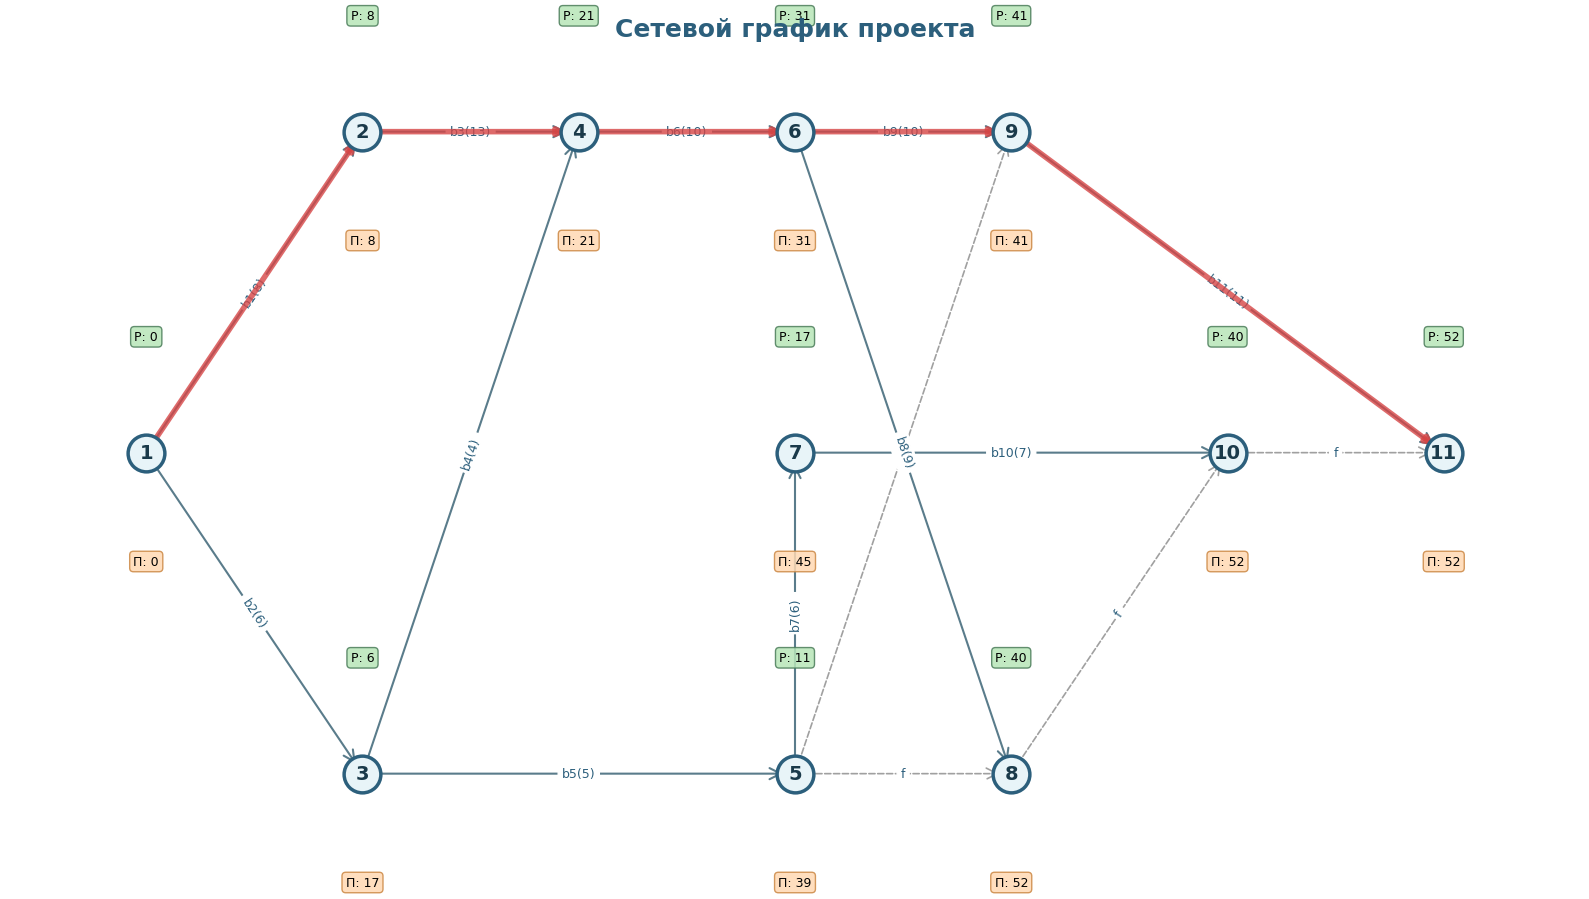

In [42]:
import matplotlib.pyplot as plt
import networkx as nx

# =============================================================================
# БЛОК ВЫВОДА РЕЗУЛЬТАТОВ
# =============================================================================

def print_cpm_results(T_critical, earliest_start, latest_start, 
                      critical_path_nodes, critical_works, total_float, 
                      free_float, tension_coeff, T_dir):
    """Вывод результатов CPM анализа"""
    print("\n")
    print("┌" + "─" * 78 + "┐")
    print("│" + "АНАЛИЗ СЕТЕВОГО ГРАФИКА".center(78) + "│")
    print("└" + "─" * 78 + "┘")
    
    print(f"\n▸ Критическое время проекта: {T_critical} дней")
    
    print("\n┌─ Ранние сроки событий")
    for node in sorted(earliest_start.keys()):
        print(f"│  Событие {node:2d} → {earliest_start[node]:3d} дней")
    
    print("\n┌─ Поздние сроки событий")
    for node in sorted(latest_start.keys()):
        print(f"│  Событие {node:2d} → {latest_start[node]:3d} дней")
    
    print(f"\n▸ Критические события: {', '.join(map(str, sorted(critical_path_nodes)))}")
    
    print("\n┌─ Критические работы")
    for work in critical_works:
        print(f"│  • {work}")
    
    print("\n┌─ Полные резервы времени")
    for (u, v), tf in total_float.items():
        status = "[КРИТИЧЕСКАЯ]" if tf == 0 else f"резерв {tf:2d} дн."
        print(f"│  ({u:2d} → {v:2d}) : {status}")
    
    print("\n┌─ Свободные резервы времени")
    for (u, v), ff in free_float.items():
        print(f"│  ({u:2d} → {v:2d}) : {ff:2d} дн.")
    
    print("\n┌─ Коэффициенты напряженности")
    for edge, coeff in tension_coeff.items():
        if coeff > 0.8:
            zone = "КРИТИЧЕСКАЯ"
        elif 0.6 <= coeff <= 0.8:
            zone = "ПОДКРИТИЧЕСКАЯ"
        else:
            zone = "РЕЗЕРВНАЯ"
        print(f"│  ({edge[0]:2d} → {edge[1]:2d}) : {coeff:.3f} [{zone}]")
    
    print("\n" + "─" * 80)
    print(f"Директивный срок  : {T_dir} дней")
    print(f"Расчетный срок    : {T_critical} дней")
    
    if T_critical <= T_dir:
        reserve = T_dir - T_critical
        print(f"Статус            : Проект в рамках срока (резерв +{reserve} дн.)")
    else:
        overtime = T_critical - T_dir
        print(f"Статус            : Превышение срока на {overtime} дн.")
    print("─" * 80)


def print_pert_3param_results(pert_data, t_expected_3param, variance_3param):
    """Вывод результатов трехпараметрической модели PERT"""
    print("\n")
    print("┌" + "─" * 78 + "┐")
    print("│" + "ТРЕХПАРАМЕТРИЧЕСКАЯ МОДЕЛЬ PERT".center(78) + "│")
    print("└" + "─" * 78 + "┘")
    
    print("\n{:<10} {:>8} {:>8} {:>8} {:>10} {:>10}".format(
        "Работа", "t_пес", "t_вер", "t_опт", "t_ож", "σ²"))
    print("─" * 60)
    
    for activity, data in pert_data.items():
        print("{:<10} {:>8} {:>8} {:>8} {:>10.2f} {:>10.2f}".format(
            activity,
            data['t_pes'],
            data['t_ver'],
            data['t_opt'],
            t_expected_3param[activity],
            variance_3param[activity]
        ))


def print_pert_2param_results(pert_data, t_expected_2param, variance_2param):
    """Вывод результатов двухпараметрической модели PERT"""
    print("\n")
    print("┌" + "─" * 78 + "┐")
    print("│" + "ДВУХПАРАМЕТРИЧЕСКАЯ МОДЕЛЬ PERT".center(78) + "│")
    print("└" + "─" * 78 + "┘")
    
    print("\n{:<10} {:>8} {:>8} {:>12} {:>10}".format(
        "Работа", "t_пес", "t_опт", "t*_ож", "σ²"))
    print("─" * 55)
    
    for activity, data in pert_data.items():
        print("{:<10} {:>8} {:>8} {:>12.2f} {:>10.2f}".format(
            activity,
            data['t_pes'],
            data['t_opt'],
            t_expected_2param[activity],
            variance_2param[activity]
        ))


def print_probability_analysis_3param(T_expected, variance, std_dev, 
                                      probability, lower_bound, upper_bound, 
                                      T_max, gamma):
    """Вывод вероятностного анализа для трехпараметрической модели"""
    print("\n")
    print("┌" + "─" * 78 + "┐")
    print("│" + "ВЕРОЯТНОСТНЫЙ АНАЛИЗ (3-параметрическая)".center(78) + "│")
    print("└" + "─" * 78 + "┘")
    
    print(f"\n▸ Ожидаемое время T_ож           : {T_expected:.2f} дней")
    print(f"▸ Дисперсия σ²_кр                : {variance:.2f}")
    print(f"▸ СКО σ_кр                       : {std_dev:.2f} дней")
    print(f"\n▸ Вероятность к сроку {T_expected:.2f}  : {probability:.2%}")
    print(f"▸ Интервал 3σ (P=0.9973)         : [{lower_bound:.1f} — {upper_bound:.1f}] дней")
    print(f"▸ Макс. срок (γ={gamma})          : {T_max:.1f} дней")


def print_probability_analysis_2param(T_expected, variance, std_dev, 
                                      probability, lower_bound, upper_bound, 
                                      T_max, gamma):
    """Вывод вероятностного анализа для двухпараметрической модели"""
    print("\n")
    print("┌" + "─" * 78 + "┐")
    print("│" + "ВЕРОЯТНОСТНЫЙ АНАЛИЗ (2-параметрическая)".center(78) + "│")
    print("└" + "─" * 78 + "┘")
    
    print(f"\n▸ Ожидаемое время T*_ож          : {T_expected:.2f} дней")
    print(f"▸ Дисперсия σ²_кр                : {variance:.2f}")
    print(f"▸ СКО σ_кр                       : {std_dev:.2f} дней")
    print(f"\n▸ Вероятность к сроку {T_expected:.2f}  : {probability:.2%}")
    print(f"▸ Интервал 3σ (P=0.9973)         : [{lower_bound:.1f} — {upper_bound:.1f}] дней")
    print(f"▸ Макс. срок (γ={gamma})          : {T_max:.1f} дней")


def print_optimization_results(T_original, T_dir, optimization_steps, 
                               total_cost_reduction, final_duration, 
                               reductions_applied, costs, S):
    """Вывод результатов оптимизации"""
    print("\n")
    print("┌" + "─" * 78 + "┐")
    print("│" + "ОПТИМИЗАЦИЯ СРОКОВ И СТОИМОСТИ".center(78) + "│")
    print("└" + "─" * 78 + "┘")
    
    print(f"\n┌─ Исходные параметры")
    print(f"│  Директивный срок T_dir         : {T_dir:.2f} дней")
    print(f"│  Стоимость дня проекта S        : {S} у.е.")
    print(f"│  Исходная продолжительность     : {T_original} дней")
    print(f"│  Требуемое сокращение           : {T_original - T_dir:.2f} дней")
    
    print(f"\n┌─ Процесс оптимизации")
    print(f"│  {'Работа':<12} {'Сокр.':<8} {'Стоим.':<10} {'Длит-ть':<10}")
    print(f"│  {'-'*45}")
    
    for step in optimization_steps:
        print(f"│  {str(step['edge']):<12} {step['reduction']:<8.0f} "
              f"{step['cost']:<10.2f} {step['duration']:<10.2f}")
    
    print(f"\n{'─'*80}")
    print(f"ИТОГОВЫЕ ПОКАЗАТЕЛИ:")
    print(f"  Продолжительность проекта      : {final_duration:.2f} дней")
    print(f"  Стоимость сокращения           : {total_cost_reduction:.2f} у.е.")
    print(f"  Общая стоимость проекта        : {total_cost_reduction + S * final_duration:.2f} у.е.")
    print(f"{'─'*80}")
    
    print(f"\n┌─ Детализация сокращений")
    for edge, reduction in reductions_applied.items():
        print(f"│  {str(edge):<12} : -{reduction:.2f} дн. → {costs[edge] * reduction:.2f} у.е.")


def visualize_network_graph(G, pos, earliest_start, latest_start, 
                            critical_path_edges):
    """Визуализация сетевого графа"""
    plt.figure(figsize=(16, 9))
    
    # Узлы
    nx.draw_networkx_nodes(G, pos, node_size=700, 
                          node_color='#E8F4F8', 
                          edgecolors='#2C5F7C', 
                          linewidths=2.5)
    
    # Обычные рёбра
    solid_edges = [(u, v) for u, v in G.edges() if G[u][v]['weight'] > 0]
    nx.draw_networkx_edges(G, pos, edgelist=solid_edges, 
                          arrows=True,
                          arrowstyle='->', 
                          arrowsize=20, 
                          edge_color='#5A7C8B',
                          width=1.5)
    
    # Фиктивные рёбра
    dashed_edges = [(u, v) for u, v in G.edges() if G[u][v]['weight'] == 0]
    nx.draw_networkx_edges(G, pos, edgelist=dashed_edges, 
                          arrows=True,
                          arrowstyle='->', 
                          arrowsize=20, 
                          edge_color='#A0A0A0',
                          style='dashed',
                          width=1.2)
    
    # Номера узлов
    nx.draw_networkx_labels(G, pos, font_size=14, 
                           font_weight='bold',
                           font_color='#1A3A4A')
    
    # Метки рёбер
    edge_labels = {}
    for (u, v), data in G.edges.items():
        if data['weight'] > 0:
            edge_labels[(u, v)] = data['label']
        else:
            edge_labels[(u, v)] = 'f'
    
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, 
                                font_size=9,
                                font_color='#2C5F7C')
    
    # Ранние и поздние сроки
    for node in G.nodes():
        x, y = pos[node]
        plt.text(x, y + 0.35, f'Р: {earliest_start[node]}', 
                fontsize=9, 
                ha='center',
                bbox=dict(facecolor='#B8E6B8', 
                         alpha=0.85, 
                         edgecolor='#4A7C59', 
                         boxstyle='round,pad=0.3',
                         linewidth=1))
        plt.text(x, y - 0.35, f'П: {latest_start[node]}', 
                fontsize=9, 
                ha='center',
                bbox=dict(facecolor='#FFD9B3', 
                         alpha=0.85, 
                         edgecolor='#CC8844', 
                         boxstyle='round,pad=0.3',
                         linewidth=1))
    
    # Критический путь
    nx.draw_networkx_edges(G, pos, edgelist=critical_path_edges, 
                          width=4.0, 
                          edge_color='#D64545', 
                          alpha=0.8)
    
    plt.title('Сетевой график проекта', 
             fontsize=18, 
             fontweight='bold',
             color='#2C5F7C',
             pad=20)
    plt.axis('off')
    plt.tight_layout()
    plt.show() 

# Позиции узлов
pos = {
    1: (0, 0),
    2: (2, 1),
    3: (2, -1),
    4: (4, 1),
    5: (6, -1),
    6: (6, 1),
    7: (6, 0),
    8: (8, -1),
    9: (8, 1),
    10: (10, 0),
    11: (12, 0)
}
 
print_cpm_results(T_critical, earliest_start, latest_start, 
                  critical_path_nodes, critical_works, total_float, 
                  free_float, tension_coeff, T_dir)

print_pert_3param_results(pert_data, t_expected_3param, variance_3param)

print_pert_2param_results(pert_data, t_expected_2param, variance_2param)

print_probability_analysis_3param(T_expected_3param, variance_critical_3param,
                                  std_3param, prob_3param, lower_3param, 
                                  upper_3param, T_max_3param, gamma)

print_probability_analysis_2param(T_expected_2param, variance_critical_2param,
                                  std_2param, prob_2param, lower_2param, 
                                  upper_3param, T_max_2param, gamma)

print_optimization_results(T_critical, T_expected_3param, opt_steps,
                          total_cost_red, final_duration, reductions, 
                          costs, S)

visualize_network_graph(G, pos, earliest_start, latest_start, 
                       critical_path_edges)